# Time Series: Advanced Assignment Part 1
## Using Facebook Prophet for forecasting
Student Name: Ariful Islam Riane (3981886), Pedro Fernandez Tonso (3983781)

Group No: 19

In this assignment you will work with facebook prohet algorithm. We need two datasets for this assignmnet both are provided via canvas. 

## Basic Exercise

In [1]:
# Load packages
from pathlib import Path
import pandas as pd # for data manipulation
import numpy as np # numerical work
import matplotlib.pyplot as plt # plotting
import datetime as dt # for date time
import prophet as ph # for prophet

Importing plotly failed. Interactive plots will not work.


In [2]:
# Read_data
# Importing data
datapath = Path.cwd().parent / "databank" / "elec_vict.csv"
df = pd.read_csv(datapath, na_values=['nan','?'])
df.head()

,Time,Demand,Temperature,Date,Holiday
0,2011-12-31T13:00:00Z,4382.825174,21.40,2012-01-01,True
1,2011-12-31T13:30:00Z,4263.365526,21.05,2012-01-01,True
2,2011-12-31T14:00:00Z,4048.966046,20.70,2012-01-01,True
3,2011-12-31T14:30:00Z,3877.563330,20.55,2012-01-01,True
4,2011-12-31T15:00:00Z,4036.229746,20.40,2012-01-01,True


### Exercise 1: Data Visulization

In [3]:
# First convert the time to data time object
df['Time'] = pd.to_datetime(df['Time'])
# Remove the time zone information
df['Time'] = df['Time'].dt.tz_localize(None)
# Set time as index
df = df.set_index('Time')
df.head()

,Demand,Temperature,Date,Holiday
Time,,,,
2011-12-31 13:00:00,4382.825174,21.40,2012-01-01,True
2011-12-31 13:30:00,4263.365526,21.05,2012-01-01,True
2011-12-31 14:00:00,4048.966046,20.70,2012-01-01,True
2011-12-31 14:30:00,3877.563330,20.55,2012-01-01,True
2011-12-31 15:00:00,4036.229746,20.40,2012-01-01,True


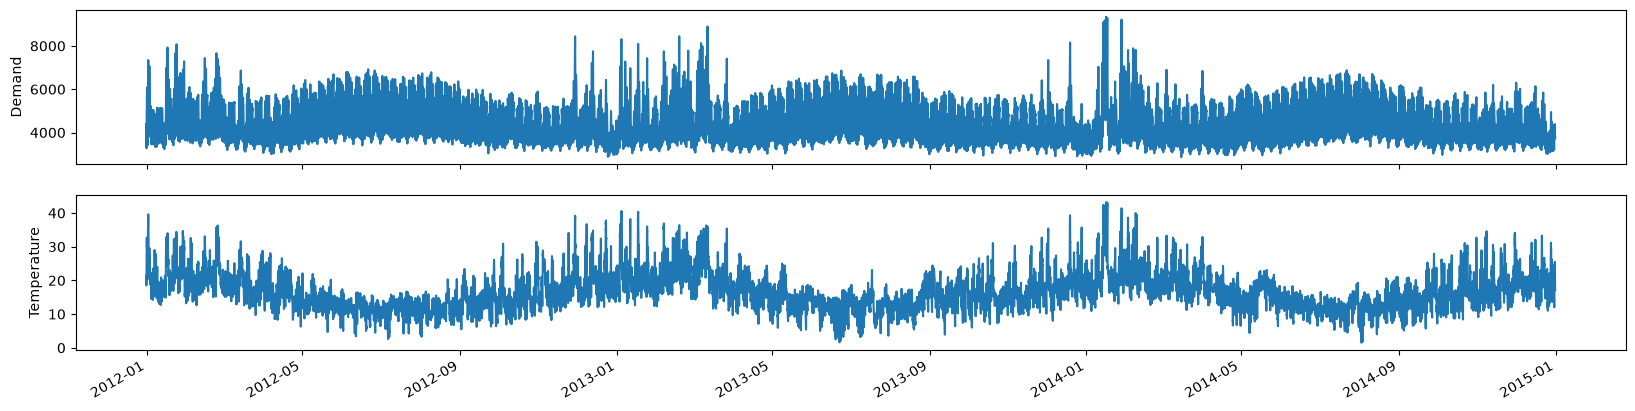

In [4]:
# Let us first plot demand and temprature (see output below)

fig, axes = plt.subplots(2, 1, figsize=(20,5), sharex=True)
axes[0].plot(df.index, df.Demand)
axes[0].set_ylabel('Demand')
axes[1].plot(df.index, df.Temperature)
axes[1].set_ylabel('Temperature')
fig.autofmt_xdate()
plt.show()

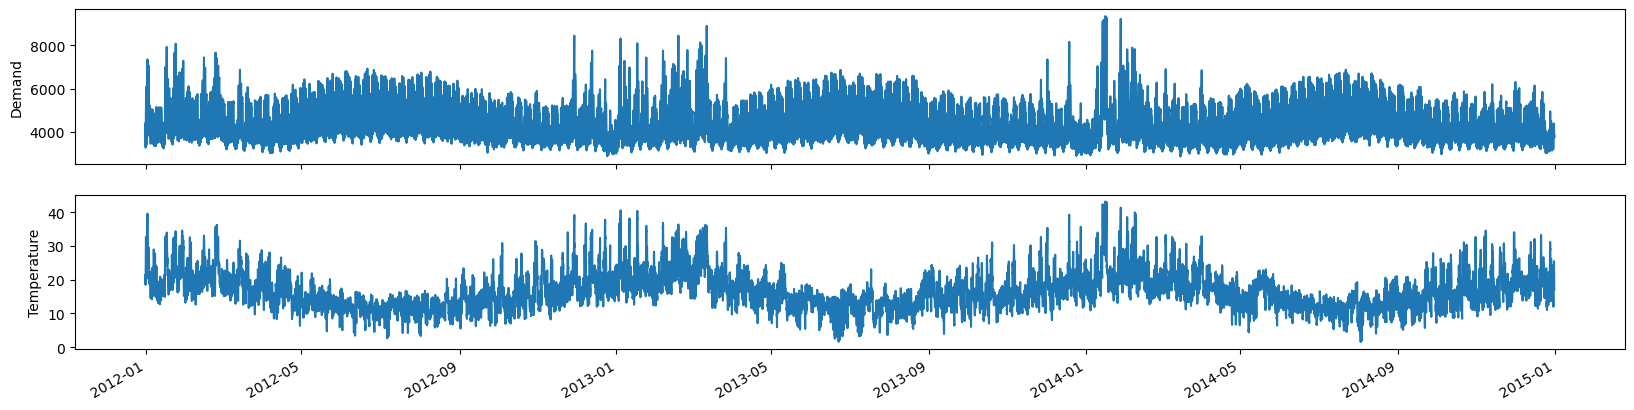

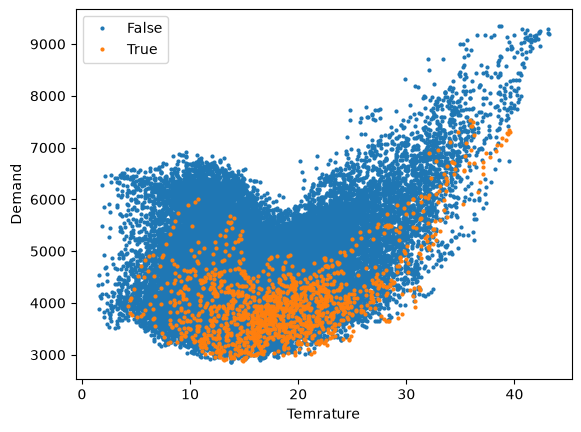

In [5]:
# Now plot temprature vs demand with Holiday (see example output below)
fig, ax = plt.subplots()
for holiday, group in df.groupby('Holiday'):
    ax.plot(group.Temperature, group.Demand, 'o', markersize=2, label=holiday)
ax.set_xlabel('Temrature')
ax.set_ylabel('Demand')
ax.legend()
plt.show()

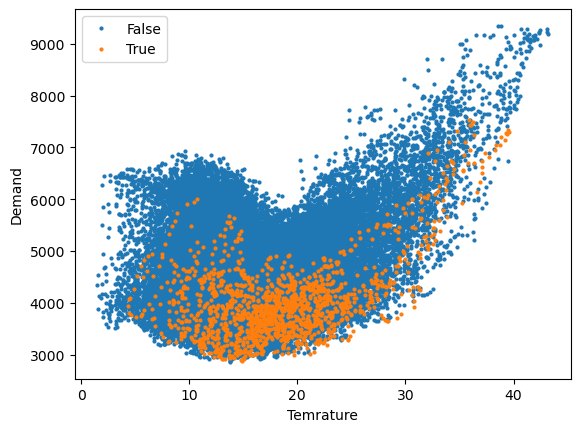

## Forecasting Using Facebook Prophet

In [6]:
# As a first step we create a time series acceptable for Prophet
ts=pd.DataFrame({'ds':df.index,'y':df.Demand})
ts.head()

,ds,y
Time,,
2011-12-31 13:00:00,2011-12-31 13:00:00,4382.825174
2011-12-31 13:30:00,2011-12-31 13:30:00,4263.365526
2011-12-31 14:00:00,2011-12-31 14:00:00,4048.966046
2011-12-31 14:30:00,2011-12-31 14:30:00,3877.563330
2011-12-31 15:00:00,2011-12-31 15:00:00,4036.229746


In [7]:
# We start by invoking Prophet 
prophet=ph.Prophet(changepoint_prior_scale=0.01)
prophet.fit(ts)





13:54:55 - cmdstanpy - INFO - Chain [1] start processing


13:55:17 - cmdstanpy - INFO - Chain [1] done processing


In [8]:
# create a future data frame 
# forecast for next 6 months, with freq='H'
future = prophet.make_future_dataframe(periods=6*30*24, freq='h')
forecast = prophet.predict(future)

In [9]:
# display the most critical output columns from the forecast
forecast[['ds','yhat','yhat_lower','yhat_upper']].head()



,ds,yhat,yhat_lower,yhat_upper
0,2011-12-31 13:00:00,3317.594476,2717.561021,3952.462953
1,2011-12-31 13:30:00,3257.735665,2647.573060,3876.534482
2,2011-12-31 14:00:00,3184.277943,2548.718282,3796.614857
3,2011-12-31 14:30:00,3085.679440,2411.460387,3708.430397
4,2011-12-31 15:00:00,2958.581532,2329.142940,3620.192200


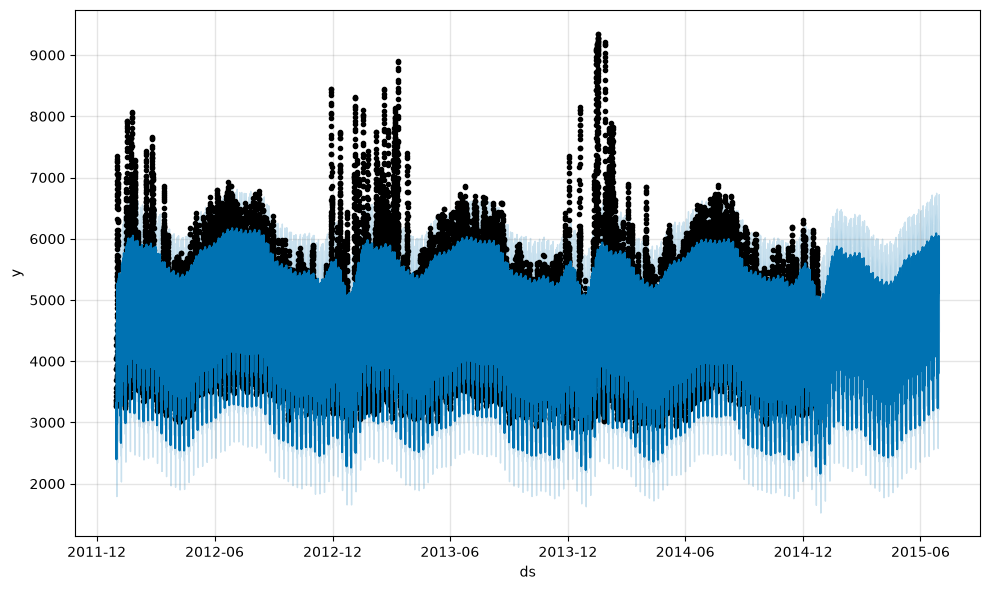

In [10]:
# plot the forecast
fig = prophet.plot(forecast)

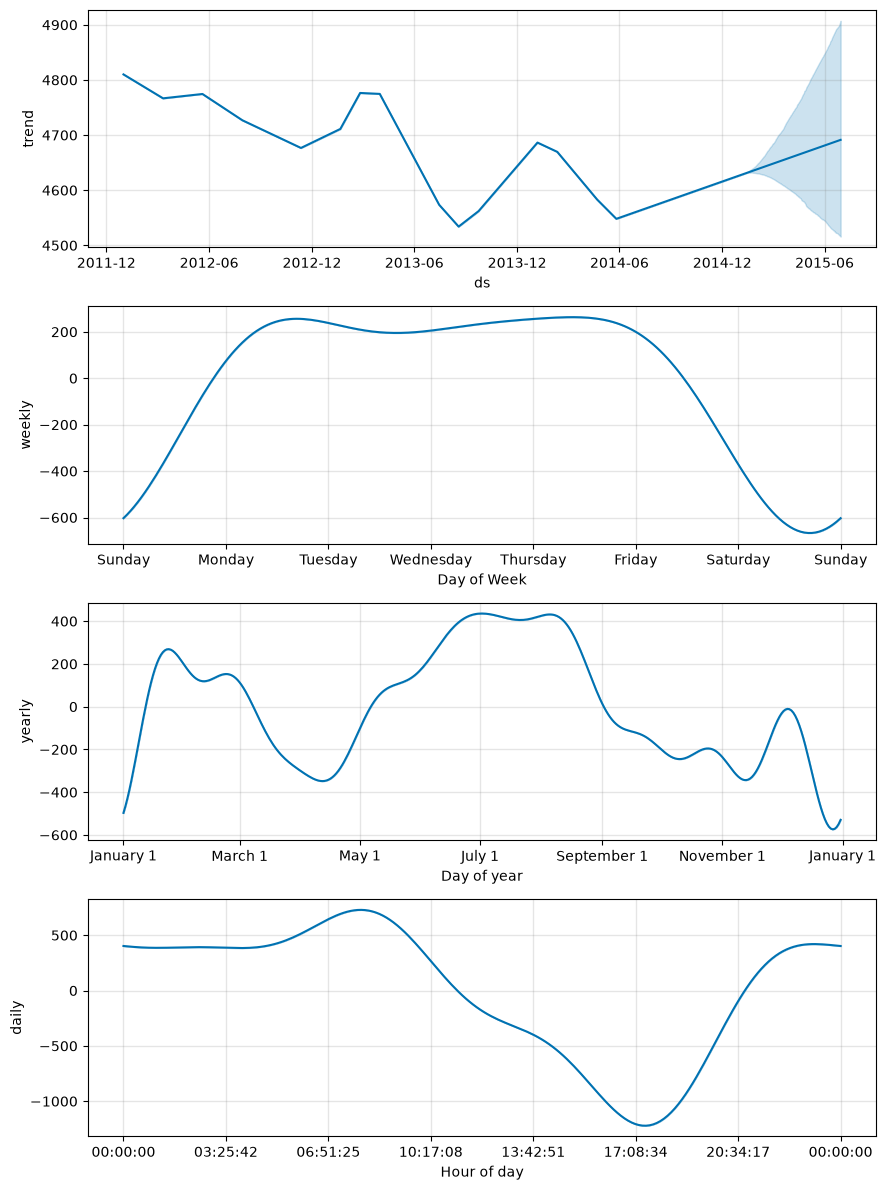

In [11]:
# Plot forecast components (example outpur given below)
fig = prophet.plot_components(forecast)

The timestamps are UTC (Victoria is UTC+10/+11), so the 07:00 UTC daily peak is the local evening peak. Demand drops on weekends and peaks in summer and winter. The forecast repeats these patterns but misses heat-wave spikes, since temperature is not a regressor.

## Regular 

Consider the dataset uselec used for the basic exercise. You must have fit a ARIMA model to that dataset. Your exercise is to fit a prediction model using Prophet and compare the results. Your code can come down here. 

Both models are fit on the log of `usmelec` with the last 36 months held out and scored in the original units. The ARIMA is the SARIMA(2,1,2)(0,1,1)[12] from the previous lab.

In [12]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

us = pd.read_csv(Path.cwd().parent.parent / "lab-3-dt" / "databank" / "usmelec.csv")
us = pd.DataFrame({'ds': pd.to_datetime(us['index'], format='%Y %b'), 'y': us['value']})

horizon = 36
train, test = us.iloc[:-horizon], us.iloc[-horizon:]
print(f"train: {train.ds.min():%Y-%m} to {train.ds.max():%Y-%m} ({len(train)} months)")
print(f"test:  {test.ds.min():%Y-%m} to {test.ds.max():%Y-%m} ({len(test)} months)")

train: 1973-01 to 2010-06 (450 months)
test:  2010-07 to 2013-06 (36 months)


In [13]:
# SARIMA from the previous lab, refit on the training part of the log series
log_train = np.log(train.set_index('ds')['y'].asfreq('MS'))
arima = SARIMAX(log_train, order=(2, 1, 2), seasonal_order=(0, 1, 1, 12),
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=500)
arima_fc = arima.get_forecast(horizon)
arima_pred = np.exp(arima_fc.predicted_mean.values)
arima_ci = np.exp(arima_fc.conf_int().values)

In [14]:
# Prophet on the same log series: yearly seasonality only, monthly data
us_prophet = ph.Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
us_prophet.fit(train.assign(y=np.log(train.y)))
us_future = us_prophet.make_future_dataframe(periods=horizon, freq='MS')
us_forecast = us_prophet.predict(us_future)
prophet_fc = us_forecast.iloc[-horizon:]
prophet_pred = np.exp(prophet_fc.yhat.values)

13:55:54 - cmdstanpy - INFO - Chain [1] start processing


13:55:54 - cmdstanpy - INFO - Chain [1] done processing


In [15]:
def metrics(y, yhat):
    err = y - yhat
    return {'RMSE': np.sqrt(np.mean(err**2)), 'MAE': np.mean(np.abs(err)), 'MAPE (%)': 100*np.mean(np.abs(err/y))}

pd.DataFrame({'SARIMA(2,1,2)(0,1,1)[12]': metrics(test.y.values, arima_pred),
              'Prophet': metrics(test.y.values, prophet_pred)}).T.round(3)

,RMSE,MAE,MAPE (%)
"SARIMA(2,1,2)(0,1,1)[12]",11.601,10.266,3.046
Prophet,14.828,13.269,3.984


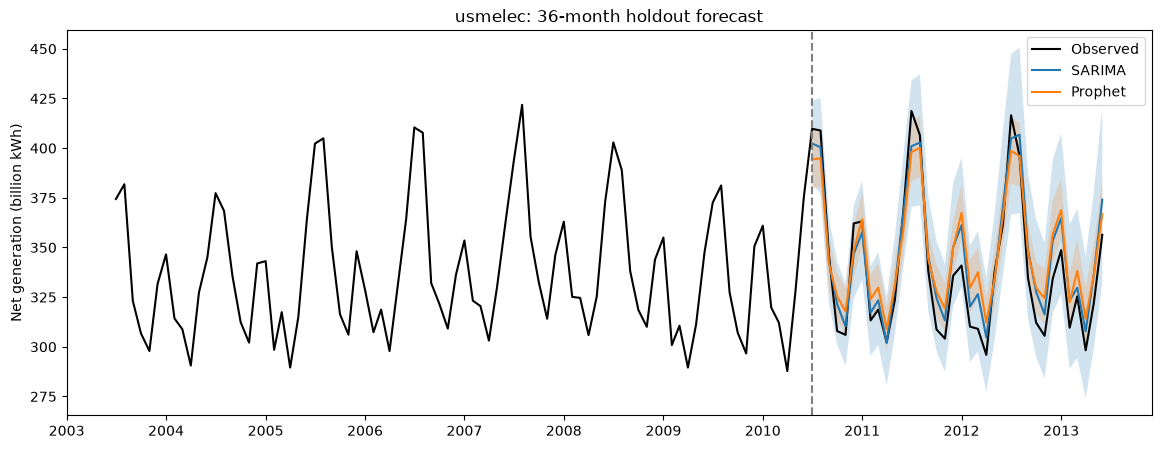

In [16]:
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(us.ds.iloc[-120:], us.y.iloc[-120:], color='black', label='Observed')
ax.plot(test.ds, arima_pred, label='SARIMA')
ax.fill_between(test.ds, arima_ci[:,0], arima_ci[:,1], alpha=0.2)
ax.plot(test.ds, prophet_pred, label='Prophet')
ax.fill_between(test.ds, np.exp(prophet_fc.yhat_lower), np.exp(prophet_fc.yhat_upper), alpha=0.2)
ax.axvline(test.ds.iloc[0], color='grey', linestyle='--')
ax.set_ylabel('Net generation (billion kWh)')
ax.set_title('usmelec: 36-month holdout forecast')
ax.legend()
plt.show()

SARIMA wins on every metric (MAPE 3.0% against 4.0%). Prophet flattens the summer peaks because its yearly seasonality is a smooth Fourier series, and its intervals are narrower since they ignore model uncertainty. Prophet needs far less tuning, but here the identified SARIMA forecasts better.